<a href="https://colab.research.google.com/github/yiyangchen2020-afk/-econ3916-midterm-project/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [314]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [315]:
SOURCE_URL = "https://api.census.gov/data/2024/acs/acs5/profile.html"
DOWNLOAD_DATE = "2026-10-26"
FILE_NAME = "data/acs_2024_counties (1).csv"

**Who collected it, for what purpose, what is missing and why?**

The data is from the 2024 ACS 5-Year Data Profiles of the US Census Bureau. This survey provides information about the population and economy of the United States. The dataset includes 3,222 counties and corresponding areas, including 78 regions in Puerto Rico. The median household income in De Baca County, New Mexico is missing and is recorded as -666666666. The exact reason is not yet clear. After excluding Puerto Rico and this missing value, there are 3,143 observation records remaining. I consider the missing income value as missing completely at random (MCAR) as a working assumption. However, this assumption cannot be verified with just one missing value.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

Research Question

How is the share of adults aged 25 or older with a bachelor's degree or higher related to median household income across U.S. counties, controlling for state differences and the share of people aged 65 or older?

Why It Matters

This question matters because education and household income are important measures of economic conditions. The results may help researchers and policymakers better understand income differences across U.S. counties.

In [316]:

import pandas as pd
import numpy as np

# Load the cleaned 2024 ACS county data from GitHub
url = "https://raw.githubusercontent.com/yiyangchen2020-afk/-econ3916-midterm-project/refs/heads/main/data/acs_2024_counties%20(1).csv"

df = pd.read_csv(
    url,
    dtype={"state": str, "county": str}
)

print("Final observations:", len(df))
display(df.head())


Final observations: 3143


,NAME,income,education,unemployment,age65_count,population,state,county,age65
0,"Autauga County, Alabama",72481.0,29.1,2.4,9759,59947,01,001,16.279380
1,"Baldwin County, Alabama",78775.0,33.7,3.0,53523,246989,01,003,21.670196
2,"Barbour County, Alabama",46042.0,10.6,7.8,4955,24643,01,005,20.107130
3,"Bibb County, Alabama",52541.0,11.7,12.1,3846,22130,01,007,17.379123
4,"Blount County, Alabama",64190.0,15.8,5.0,11067,59518,01,009,18.594375


In [317]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = ""        "county"
OUTCOME = ""     "income"
MAIN_X = ""      "education"
CONTROLS =     ["age65"]

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 3,143   Columns: 9   One row is: county

Missing values per column:
income       0
education    0
age65        0

Skew of income: 1.25 (above about 1, consider a log)


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?

*Your answers here.*

1. Education may affect unemployment, which could make unemployment a bad control. Therefore, I excluded unemployment from the models. Age is included because it may affect both education and income.

2. All variables come from the 2024 ACS 5-Year Data Profiles. They use county-level data from the same survey period.

3. This study does not examine a policy change, so data from before a policy is not needed.

In [318]:
variables = ["income", "education", "unemployment", "age65"]

summary = df[variables].describe().T

summary = summary.rename(columns={
    "count": "N",
    "mean": "Mean",
    "50%": "Median",
    "std": "SD",
    "min": "Min",
    "max": "Max"
})

summary = summary[["Mean", "Median", "SD", "Min", "Max", "N"]]

summary["N"] = summary["N"].astype(int)
display(summary.round(2))

,Mean,Median,SD,Min,Max,N
income,67976.43,65681.0,17774.48,22188.00,181765.00,3143
education,24.69,22.2,10.29,0.00,80.50,3143
unemployment,4.66,4.4,2.41,0.00,28.60,3143
age65,20.44,20.0,5.08,4.47,81.82,3143


In [319]:
print("Number of states:", df["state"].nunique())
print("State codes:", sorted(df["state"].unique()))

Number of states: 51
State codes: ['01', '02', '04', '05', '06', '08', '09', '10', '11', '12', '13', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '44', '45', '46', '47', '48', '49', '50', '51', '53', '54', '55', '56']


## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

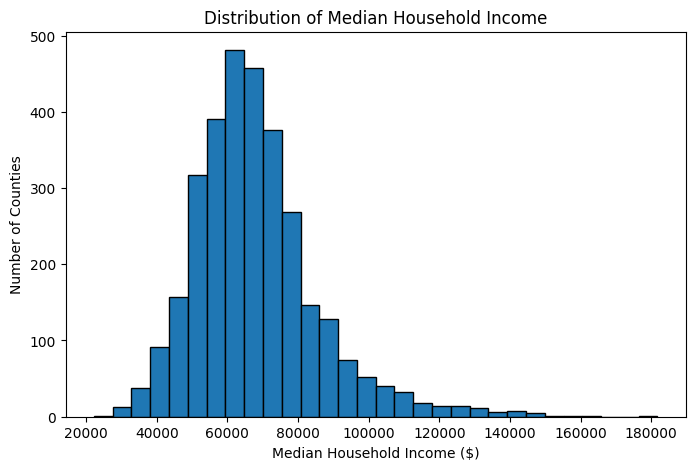

In [320]:
plt.figure(figsize=(8, 5))
plt.hist(df["income"], bins=30, edgecolor="black")
plt.xlabel("Median Household Income ($)")
plt.ylabel("Number of Counties")
plt.title("Distribution of Median Household Income")
plt.show()

Figure 1. Median household income is right-skewed. Most counties have lower or middle income levels, while a smaller number of counties have much higher incomes.

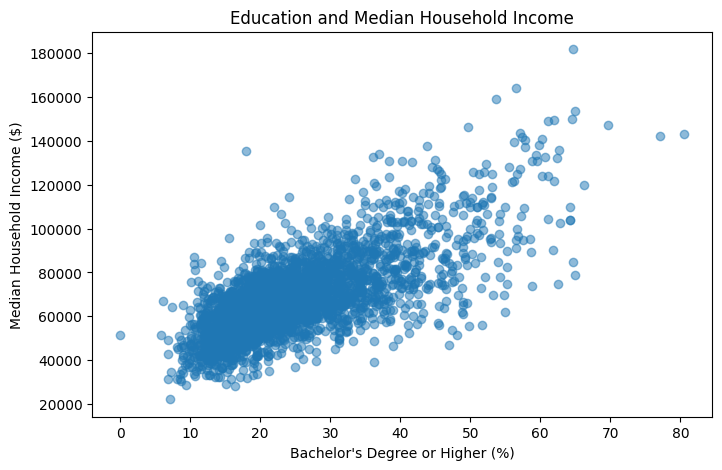

In [321]:
plt.figure(figsize=(8, 5))
plt.scatter(df["education"], df["income"], alpha=0.5)
plt.xlabel("Bachelor's Degree or Higher (%)")
plt.ylabel("Median Household Income ($)")
plt.title("Education and Median Household Income")
plt.show()

Figure 2. Counties with a higher share of adults holding a bachelor's degree or higher tend to have higher median household income. However, the relationship does not imply causation.

In [322]:
df["log_income"] = np.log(df["income"])

print("Income skewness:", round(df["income"].skew(), 2))
print("Log income skewness:", round(df["log_income"].skew(), 2))

Income skewness: 1.25
Log income skewness: 0.16


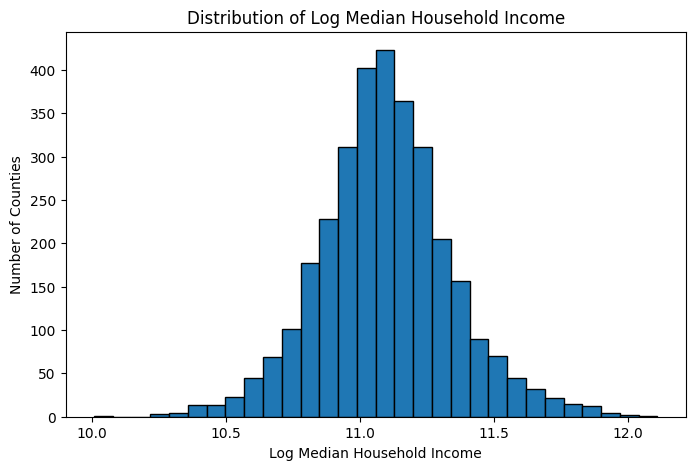

In [323]:
plt.figure(figsize=(8, 5))
plt.hist(df["log_income"], bins=30, edgecolor="black")
plt.xlabel("Log Median Household Income")
plt.ylabel("Number of Counties")
plt.title("Distribution of Log Median Household Income")
plt.show()

Figure 3. The distribution of log median household income is less right-skewed than the original income distribution. The log transformation reduces skewness from 1.2538 to 0.1640.

Median household income is right-skewed, with a skewness of 1.25. After taking the natural log, skewness decreases to 0.16. Counties with higher education levels also tend to have higher household incomes. These relationships do not show causation.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [324]:
import statsmodels.api as sm

X1 = sm.add_constant(df[["education"]])
y = df["log_income"]

model1 = sm.OLS(y, X1).fit(cov_type="HC3")

print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:             log_income   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.480
Method:                 Least Squares   F-statistic:                     2021.
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:10:02   Log-Likelihood:                 941.09
No. Observations:                3143   AIC:                            -1878.
Df Residuals:                    3141   BIC:                            -1866.
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         10.6819      0.009   1125.183      0.0

In [325]:
import statsmodels.formula.api as smf

model2 = smf.ols(
    "log_income ~ education + C(state)",
    data=df
).fit(cov_type="HC3")

print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:             log_income   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.598
Method:                 Least Squares   F-statistic:                     102.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:10:02   Log-Likelihood:                 1372.7
No. Observations:                3143   AIC:                            -2641.
Df Residuals:                    3091   BIC:                            -2327.
Df Model:                          51                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         10.5990      0.024    447.

In [326]:
model3 = smf.ols(
    "log_income ~ education + age65 + C(state)",
    data=df
).fit(cov_type="HC3")

print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:             log_income   R-squared:                       0.624
Model:                            OLS   Adj. R-squared:                  0.618
Method:                 Least Squares   F-statistic:                     84.64
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        04:10:02   Log-Likelihood:                 1450.5
No. Observations:                3143   AIC:                            -2795.
Df Residuals:                    3090   BIC:                            -2474.
Df Model:                          52                                         
Covariance Type:                  HC3                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         10.7565      0.028    378.

In [327]:
models = [model1, model2, model3]

for i, model in enumerate(models, 1):
    print(f"Model {i}")
    print("Education:", round(model.params["education"], 4))
    print("SE:", round(model.bse["education"], 4))
    print("R-squared:", round(model.rsquared, 3))
    print("N:", int(model.nobs))
    print()

Model 1
Education: 0.0168
SE: 0.0004
R-squared: 0.48
N: 3143

Model 2
Education: 0.015
SE: 0.0004
R-squared: 0.605
N: 3143

Model 3
Education: 0.0143
SE: 0.0004
R-squared: 0.624
N: 3143



In [328]:
rows = ["education", "age65", "const"]

table = pd.DataFrame()

for i, model in enumerate([model1, model2, model3], 1):
    results = []

    for var in rows:
        param = "Intercept" if var == "const" and i != 1 else var

        if param in model.params:
            coef = f"{model.params[param]:.4f}"
            se = f"({model.bse[param]:.4f})"
            results.append(coef + " " + se)
        else:
            results.append("")

    table[f"Model {i}"] = results

table.index = ["education", "age65", "Constant"]

table.loc["State Dummies"] = ["No", "Yes", "Yes"]
table.loc["N"] = [int(m.nobs) for m in [model1, model2, model3]]
table.loc["R-squared"] = [
    round(model1.rsquared, 3),
    round(model2.rsquared, 3),
    round(model3.rsquared, 3)
]

display(table)

,Model 1,Model 2,Model 3
education,0.0168 (0.0004),0.0150 (0.0004),0.0143 (0.0004)
age65,,,-0.0073 (0.0008)
Constant,10.6819 (0.0095),10.5990 (0.0237),10.7565 (0.0284)
State Dummies,No,Yes,Yes
N,3143,3143,3143
R-squared,0.48,0.605,0.624


In [329]:
print(model3.conf_int().loc[["education", "age65"]])

                  0        1
education  0.013511  0.01503
age65     -0.008869 -0.00570


Among the three models, the education share and the median household income are positively related. The education coefficients in each model are 0.0168, 0.0150, and 0.0143 respectively. In Model 1, for each percentage point increase in the share of adults with a bachelor's degree or higher in a county, the median household income is typically about 1.68% higher. After adding the state dummy variables, the education coefficient drops to 0.0150; further adding the age variable, this coefficient decreases further to 0.0143. The R² values of each model are 0.480, 0.605, and 0.624 respectively.

In Model 3, under the condition of controlling for age and state factors, for each percentage point increase in the share of adults with a bachelor's degree or higher, the median household income is typically about 1.43% higher. The 95% confidence interval is 1.35% to 1.50%. For every percentage point increase in the proportion of people aged 65 and above, the median household income is on average about 0.73% lower, with a 95% confidence interval of -0.89% to -0.57%. However, these results do not indicate a causal relationship.

In Model 3, I added the age variable because age may simultaneously affect the educational level and income level. I added the state dummy variables to control for differences between states, but these variables cannot fully explain the differences between urban and rural areas within each state. Unemployment was not included because education may affect the unemployment rate, and the unemployment rate may in turn affect income. Therefore, unemployment may not be a suitable control variable.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

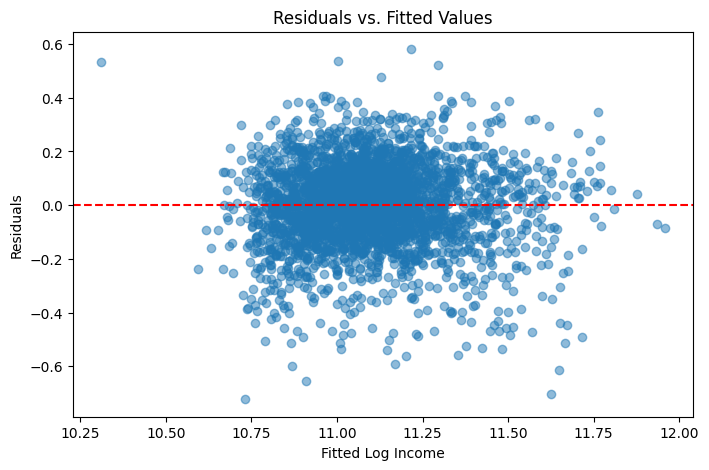

In [330]:
plt.figure(figsize=(8, 5))

plt.scatter(model3.fittedvalues, model3.resid, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Fitted Log Income")
plt.ylabel("Residuals")
plt.title("Residuals vs. Fitted Values")

plt.show()

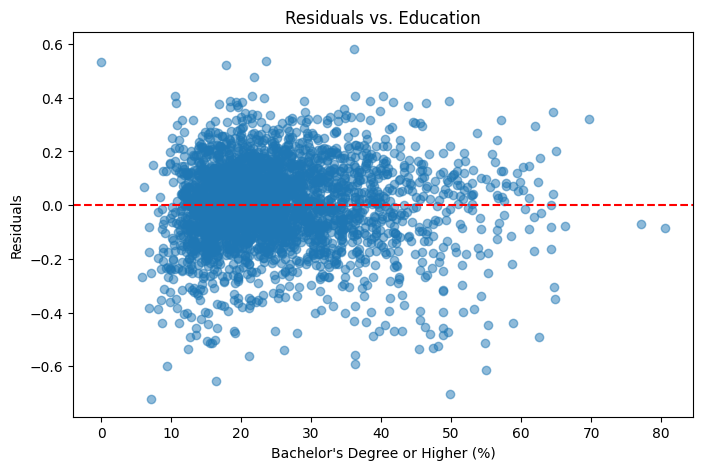

In [331]:
plt.figure(figsize=(8, 5))

plt.scatter(df["education"], model3.resid, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Bachelor's Degree or Higher (%)")
plt.ylabel("Residuals")
plt.title("Residuals vs. Education")

plt.show()

In [332]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp = het_breuschpagan(
    model3.resid,
    model3.model.exog
)

print("Breusch-Pagan p-value:", bp[1])

Breusch-Pagan p-value: 1.2412790698894138e-29


In [333]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X3_vif = model3.model.exog
names = model3.model.exog_names

vif3 = pd.DataFrame()
vif3["Variable"] = names
vif3["VIF"] = [
    variance_inflation_factor(X3_vif, i)
    for i in range(X3_vif.shape[1])
]

display(vif3[vif3["Variable"].isin(["education", "age65"])].round(2))

,Variable,VIF
51,education,1.33
52,age65,1.16


In [334]:
influence = model3.get_influence()
cooks_d = influence.cooks_distance[0]

cutoff = 4 / len(df)

print("Cook's D cutoff:", round(cutoff, 4))
print("Observations above cutoff:", (cooks_d > cutoff).sum())

Cook's D cutoff: 0.0013
Observations above cutoff: 157


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:961: RuntimeWarning: invalid value encountered in sqrt
  return self.resid / sigma / np.sqrt(1 - hii)


In [335]:
print("NaN values:", np.isnan(cooks_d).sum())

leverage = influence.hat_matrix_diag

print("Maximum leverage:", leverage.max())
print("Observations with leverage near 1:",
      (leverage > 0.9999).sum())

NaN values: 1
Maximum leverage: 1.0000000000000095
Observations with leverage near 1: 1


In [336]:
print(df.loc[leverage > 0.9999, ["NAME", "state", "county"]])

                                           NAME state county
321  District of Columbia, District of Columbia    11    001


In [337]:
cook_table = df[["NAME", "state", "county"]].copy()
cook_table["cooks_d"] = cooks_d

cook_table = cook_table.dropna(subset=["cooks_d"])

display(cook_table.nlargest(10, "cooks_d"))

,NAME,state,county,cooks_d
1753,"Esmeralda County, Nevada",32,009,0.016834
3120,"Albany County, Wyoming",56,001,0.015482
2674,"Loving County, Texas",48,301,0.014807
2991,"Whitman County, Washington",53,075,0.011748
97,"Apache County, Arizona",04,001,0.008361
68,"Aleutians West Census Area, Alaska",02,016,0.008145
1218,"Baltimore city, Maryland",24,510,0.006818
585,"Madison County, Idaho",16,065,0.004867
1145,"Lincoln Parish, Louisiana",22,061,0.004858
2033,"Sioux County, North Dakota",38,085,0.004652


In [338]:
top_counties = cook_table.nlargest(10, "cooks_d").index

df_check = df.drop(index=top_counties)

model3_check = smf.ols(
    "log_income ~ education + age65 + C(state)",
    data=df_check
).fit(cov_type="HC3")

print("Original education coefficient:",
      round(model3.params["education"], 4))

print("Without top 10 influential counties:",
      round(model3_check.params["education"], 4))

print("Original N:", int(model3.nobs))
print("New N:", int(model3_check.nobs))

Original education coefficient: 0.0143
Without top 10 influential counties: 0.0144
Original N: 3143
New N: 3133


The residual plots show no clear curve pattern. The p-value of the Breusch-Pagan test is less than 0.001, indicating the presence of heteroscedasticity. Therefore, I used HC3 robust standard errors to account for heteroscedasticity.

The VIF values for education and age were 1.33 and 1.16 respectively. These values indicate that there is no severe multicollinearity between these two variables. The Cook distance method found that 157 observations exceeded the critical value of 4/n. One observation in Washington D.C. had a leverage value of 1, and its Cook distance was undefined. After removing the 10 counties with the greatest influence, the education coefficient changed from 0.0143 to 0.0144.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

The results may be influenced by missing variables such as local industries, living costs, and the urban-rural gap. High-income counties may also attract more educated people. The unemployment rate may not be an appropriate control variable because education may affect the unemployment rate, and the unemployment rate may in turn affect income. These factors make it more difficult to accurately identify causal relationships. Therefore, the education coefficient reflects a conditional association rather than a causal relationship.

The research results show that there is a positive relationship between the educational level of counties in the United States and the median household income. In Model 3, if the proportion of adults with a bachelor's degree or higher education is 1 percentage point higher, while keeping age and state unchanged, the median household income is typically about 1.43% higher. Even if the top 10 most influential counties are removed, the results are still similar to before. However, omitted variables and reverse causality limit our interpretation of the results. If I had more time, I would include the population density of counties, so that we can better control the urban-rural gap, but these results do not establish a causal relationship.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

The regression results are reported in Section 3. The residual plots and diagnostic tests are included in Section 4. The formatted regression table and diagnostic figures are provided in the written report's appendix.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [339]:
REPORT_NUMBERS = {
    "Section 1: rows in the final sample": len(df),
    "Section 1: initial observations": 3222,
    "Section 1: Puerto Rico observations excluded": 78,
    "Section 1: missing income observations excluded": 1,
    "Section 3: coefficient on education": model3.params["education"],
    "Section 1: mean income": df["income"].mean(),
    "Section 1: median income": df["income"].median(),
    "Section 2: income skewness": df["income"].skew(),
    "Section 2: log income skewness": df["log_income"].skew(),
    "Section 3: Model 3 R-squared": model3.rsquared,
    "Section 3: education 95% CI lower": model3.conf_int().loc["education", 0],
    "Section 3: education 95% CI upper": model3.conf_int().loc["education", 1],
    "Section 4: Breusch-Pagan p-value": bp[1],
    "Section 4: Cook's D cutoff": cutoff,
    "Section 4: observations above Cook's D cutoff": int((cooks_d > cutoff).sum()),
    "Section 4: undefined Cook's D values": int(np.isnan(cooks_d).sum()),
    "Section 4: original education coefficient": model3.params["education"],
    "Section 4: original N": int(model3.nobs),
    "Section 4: education coefficient without top 10": model3_check.params["education"],
    "Section 4: N without top 10": int(model3_check.nobs),
    "Section 3: Model 1 education coefficient": model1.params["education"],
    "Section 3: Model 2 education coefficient": model2.params["education"],
    "Section 3: Model 1 R-squared": model1.rsquared,
    "Section 3: Model 2 R-squared": model2.rsquared,
    "Section 3: Model 1 N": int(model1.nobs),
    "Section 3: Model 2 N": int(model2.nobs),
    "Section 3: Model 3 N": int(model3.nobs),
    "Section 3: Model 3 age65 coefficient": model3.params["age65"],
    "Section 3: age65 95% CI lower": model3.conf_int().loc["age65", 0],
    "Section 3: age65 95% CI upper": model3.conf_int().loc["age65", 1],
    "Section 4: education VIF": vif3.loc[vif3["Variable"] == "education", "VIF"].iloc[0],
    "Section 4: age65 VIF": vif3.loc[vif3["Variable"] == "age65", "VIF"].iloc[0],
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

print("\nSection 1: Summary Statistics")

summary_report = df[
    ["income", "education", "unemployment", "age65"]
].agg(["mean", "median", "std", "min", "max", "count"]).T

display(summary_report.round(2))


Section 1: rows in the final sample: 3143
Section 1: initial observations: 3222
Section 1: Puerto Rico observations excluded: 78
Section 1: missing income observations excluded: 1
Section 3: coefficient on education: 0.014270177550264206
Section 1: mean income: 67976.42920776329
Section 1: median income: 65681.0
Section 2: income skewness: 1.2537539438557963
Section 2: log income skewness: 0.1639509334319325
Section 3: Model 3 R-squared: 0.6238490068947748
Section 3: education 95% CI lower: 0.013510522667265943
Section 3: education 95% CI upper: 0.01502983243326247
Section 4: Breusch-Pagan p-value: 1.2412790698894138e-29
Section 4: Cook's D cutoff: 0.0012726694241170856
Section 4: observations above Cook's D cutoff: 157
Section 4: undefined Cook's D values: 1
Section 4: original education coefficient: 0.014270177550264206
Section 4: original N: 3143
Section 4: education coefficient without top 10: 0.014417364756056112
Section 4: N without top 10: 3133
Section 3: Model 1 education coeff

,mean,median,std,min,max,count
income,67976.43,65681.0,17774.48,22188.00,181765.00,3143.0
education,24.69,22.2,10.29,0.00,80.50,3143.0
unemployment,4.66,4.4,2.41,0.00,28.60,3143.0
age65,20.44,20.0,5.08,4.47,81.82,3143.0


## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.